In [ ]:
import numpy as np 
import pandas as pd 
import sys
import os
print(os.getenv("PYTHONPATH"))
import to_latex as latex
from pathlib import Path
export_dir = Path('./export') # Укажите ваш путь
master_file = export_dir / 'from_python.tex'


:/home/alex/Code/MIPT_phys_lab/Mechanics/modules_latex


## Измерения значения гармоник

In [3]:
mass = (0.4919+0.4915+0.1116, 0.4919+0.4915+0.1116+0.3437, 0.4946+0.4919+0.4915+0.1116+0.3437,
0.4946+0.4919+0.4915+0.1116+0.3437+0.4590+0.4874)
len(mass)


4

In [4]:
# частота осносной гармоники
# v1 = 1/(2*0.5)*((0.3437+0.1116)*9.81/(568.4*10**(-6)))**0.5
n_uneven = (1,3,5,7,9)
n_even = (2,4,6,8,10)

teor_even = {} 
teor_list = []
for idx, m in enumerate(mass):
    print(f'масса {m}')
    for i in n_even:
        v1 = (i/(2*0.5))*(m*9.81/(568.4*10**(-6)))**0.5
        teor_list.append(v1)
        print(f"номер гармоники {i} частота = {v1}")
    teor_even[f'm{idx}'] = teor_list

масса 1.095
номер гармоники 2 частота = 274.9441757682477
номер гармоники 4 частота = 549.8883515364954
номер гармоники 6 частота = 824.832527304743
номер гармоники 8 частота = 1099.7767030729908
номер гармоники 10 частота = 1374.7208788412386
масса 1.4386999999999999
номер гармоники 2 частота = 315.1538279267148
номер гармоники 4 частота = 630.3076558534297
номер гармоники 6 частота = 945.4614837801445
номер гармоники 8 частота = 1260.6153117068593
номер гармоники 10 частота = 1575.769139633574
масса 1.9333
номер гармоники 2 частота = 365.3314749084199
номер гармоники 4 частота = 730.6629498168398
номер гармоники 6 частота = 1095.9944247252597
номер гармоники 8 частота = 1461.3258996336797
номер гармоники 10 частота = 1826.6573745420997
масса 2.8797
номер гармоники 2 частота = 445.8729113337393
номер гармоники 4 частота = 891.7458226674786
номер гармоники 6 частота = 1337.618734001218
номер гармоники 8 частота = 1783.4916453349572
номер гармоники 10 частота = 2229.3645566686964


In [5]:
# измерения гармоник для разных нагрузок

# четные гармоники
v_uneven = pd.DataFrame({'m0' : [137.0, 413.8, 692.4, 973.4, 1260.2], 
'm1' : [157.9, 475.5, 792.3, 1113.3, 1431.0],
'm2' : [182.0, 544.4, 914.2, 1275.3, 1643.1],
'm3' : [220.9, 666.3, 1107.1, 1550.0, 2000.5]})

# неченые гармоники
v_even = pd.DataFrame({'m0' : [278.8, 559.6, 825.5, 1101.4, 1366.6],
'm1' : [315.7, 634.4, 950.3, 1263.7, 1564.1],
'm2' : [368.0, 733.8, 1093, 1459, 1833.8],
'm3' : [444.7, 888.0, 1347, 1790.1, 2246.9]})

In [6]:
from scipy.optimize import curve_fit

#параметры установки:
L = 0.5
rho = 568.4*10**(-6)

def freq(n, k):
    return k*n

In [7]:
ax.legend?

Signature: ax.legend(*args, **kwargs)
Docstring:
Place a legend on the Axes.

Call signatures::

    legend()
    legend(handles, labels)
    legend(handles=handles)
    legend(labels)

The call signatures correspond to the following different ways to use
this method:

**1. Automatic detection of elements to be shown in the legend**

The elements to be added to the legend are automatically determined,
when you do not pass in any extra arguments.

In this case, the labels are taken from the artist. You can specify
them either at artist creation or by calling the
:meth:`~.Artist.set_label` method on the artist::

    ax.plot([1, 2, 3], label='Inline label')
    ax.legend()

or::

    line, = ax.plot([1, 2, 3])
    line.set_label('Label via method')
    ax.legend()

.. note::
    Specific artists can be excluded from the automatic legend element
    selection by using a label starting with an underscore, "_".
    A string starting with an underscore is the default label for all
    artist

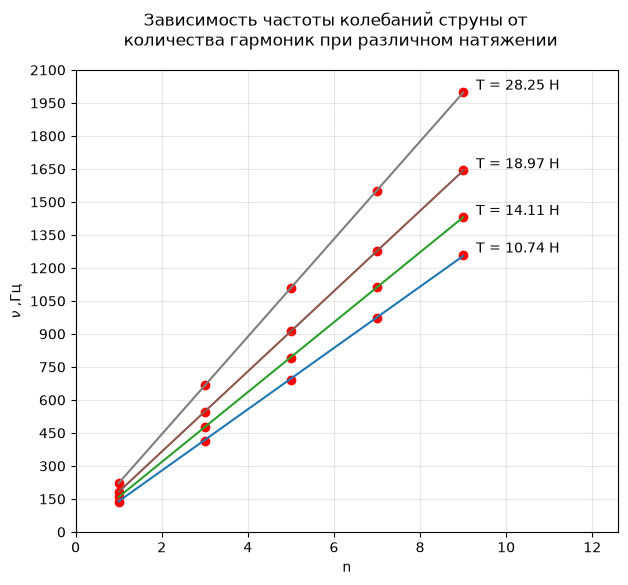

In [ ]:
import matplotlib.pyplot as plt 
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(7,6))
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(150))
colors = plt.cm.tab10(np.linspace(0, 1, 5))
count = 0
for i in v_uneven:
    k, var = curve_fit(f=freq, xdata=n_uneven, ydata=v_uneven[i])
    ax.scatter(n_uneven, v_uneven[i], color = 'red')
    plt.grid(alpha = 0.3)
    ax.set_xlabel('n')
    ax.set_ylabel(r'$\nu \text{ ,Гц}$')
    ax.set_xlim(0, 12.6)
    ax.set_ylim(0, 2100)
    #ax.axline((0, 0), slope=k)
    ax.grid(True)
    ax.plot(n_uneven, k*n_uneven, color = colors[count])
    fig.suptitle('Зависимость частоты колебаний струны от \n количества гармоник при различном натяжении')
    ax.text(9 + 0.3, v_uneven[i][4]+ 10, f'T = {(mass[count]*9.81):.2f} Н')
    count += 1
    #

In [ ]:
import sympy as sp 
from sympy import sqrt
k_sym, T_sym, n_sym, L_sym, rho_sym, u_sym = sp.symbols(r"k T n L \rho u")
koeff = (1/(2*L_sym)) * sqrt(T_sym/rho_sym)
display(sp.Eq(k_sym, koeff))

# 

Eq(k, sqrt(T/\rho)/(2*L))

In [ ]:
curve_fit?


Signature:
curve_fit(
    f,
    xdata,
    ydata,
    p0=None,
    sigma=None,
    absolute_sigma=False,
    check_finite=None,
    bounds=(-inf, inf),
    method=None,
    jac=None,
    *,
    full_output=False,
    nan_policy=None,
    **kwargs,
)
Docstring:
Use non-linear least squares to fit a function, f, to data.

Assumes ``ydata = f(xdata, *params) + eps``.

Parameters
----------
f : callable
    The model function, f(x, ...). It must take the independent
    variable as the first argument and the parameters to fit as
    separate remaining arguments.
xdata : array_like
    The independent variable where the data is measured.
    Should usually be an M-length sequence or an (k,M)-shaped array for
    functions with k predictors, and each element should be float
    convertible if it is an array like object.
ydata : array_like
    The dependent data, a length M array - nominally ``f(xdata, ...)``.
p0 : array_like, optional
    Initial guess for the parameters (length N). If None